# Exploratory Data Analysis
Explore sales patterns, product demand, seasonality, and variability to identify useful features for demand forecasting.

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [16]:
# Load cleaned data
bakery = pd.read_csv("cleaned_bakery.csv")

# Convert date column
bakery["date"] = pd.to_datetime(bakery["date"])

# Check dataset
print("Shape:", bakery.shape)
print("Products:", bakery["article"].nunique())
display(bakery.head())

Shape: (172629, 7)
Products: 26


,date,time,ticket_number,article,Quantity,unit_price,revenue
0,2021-01-02,08:38,150040.0,BAGUETTE,1.0,0.9,0.9
1,2021-01-02,08:38,150040.0,PAIN AU CHOCOLAT,3.0,1.2,3.6
2,2021-01-02,09:14,150041.0,PAIN AU CHOCOLAT,2.0,1.2,2.4
3,2021-01-02,09:25,150042.0,TRADITIONAL BAGUETTE,5.0,1.2,6.0
4,2021-01-02,09:25,150043.0,BAGUETTE,2.0,0.9,1.8


### 1. Product Sales Performance

Analyze total quantities sold by product to identify the highest-demand products

In [17]:
# Total quantity sold by product
product_sales = (
    bakery.groupby("article")["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

# Table of top products with quantities of each
display(product_sales)

,article,Quantity
0,TRADITIONAL BAGUETTE,118093.0
1,CROISSANT,29822.0
2,PAIN AU CHOCOLAT,25367.0
3,BANETTE,22870.0
4,BAGUETTE,22156.0
5,CEREAL BAGUETTE,7478.0
6,SPECIAL BREAD,5488.0
7,FORMULE SANDWICH,5285.0
8,TARTELETTE,5051.0
9,BOULE 400G,4851.0


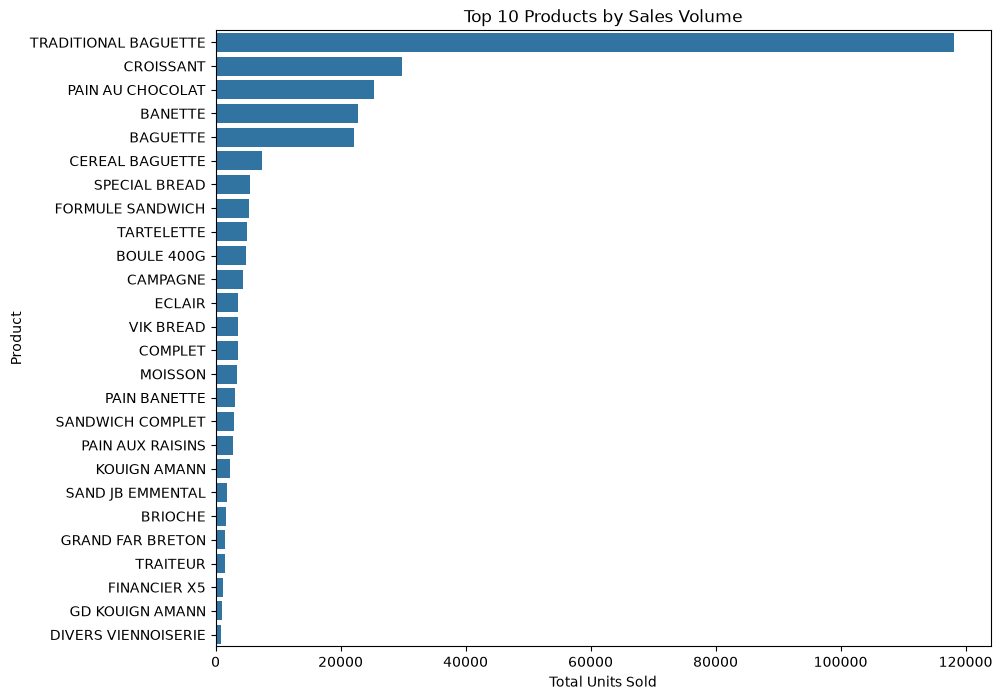

In [18]:
# Visualization
plt.figure(figsize=(10, 8))
sns.barplot(data=product_sales, x="Quantity", y="article")

plt.title("Top 10 Products by Sales Volume")
plt.xlabel("Total Units Sold")
plt.ylabel("Product")
plt.show()

### 2. Daily Sales Trends

Analyze daily sales volume to identify demand patterns and potential seasonality.

In [19]:
# Aggregate daily sales
daily_sales = bakery.groupby("date")["Quantity"].sum().reset_index()
daily_sales.head()

,date,Quantity
0,2021-01-02,447.0
1,2021-01-03,437.0
2,2021-01-04,264.0
3,2021-01-05,241.0
4,2021-01-07,236.0


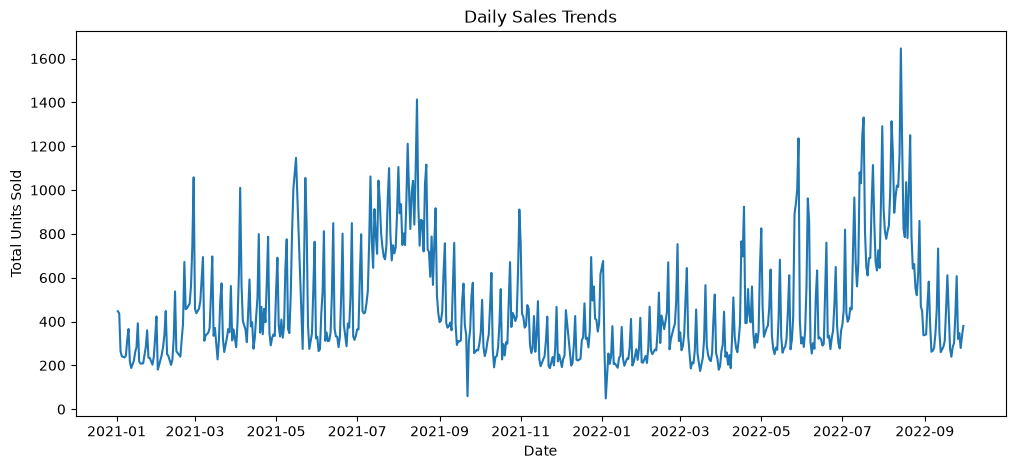

In [20]:
# Visualize daily sales
plt.figure(figsize=(12, 5))
sns.lineplot(data=daily_sales, x="date", y="Quantity")

plt.title("Daily Sales Trends")
plt.xlabel("Date")
plt.ylabel("Total Units Sold")
plt.show()

### 3. Weekly Seasonality

Analyze average daily sales by weekday to identify weekly demand patterns.

In [21]:
# Extract weekday
daily_sales["weekday"] = daily_sales["date"].dt.day_name()

# Average daily sales by weekday
weekday_sales = daily_sales.groupby("weekday")["Quantity"].mean()

# Sort weekdays
weekdays = ["Monday", "Tuesday", "Wednesday", "Thursday",
            "Friday", "Saturday", "Sunday"]

weekday_sales = weekday_sales.reindex(weekdays)

weekday_sales

weekday
Monday       434.500000
Tuesday      372.404494
Wednesday    405.548387
Thursday     400.494382
Friday       413.175824
Saturday     547.522222
Sunday       732.989011
Name: Quantity, dtype: float64

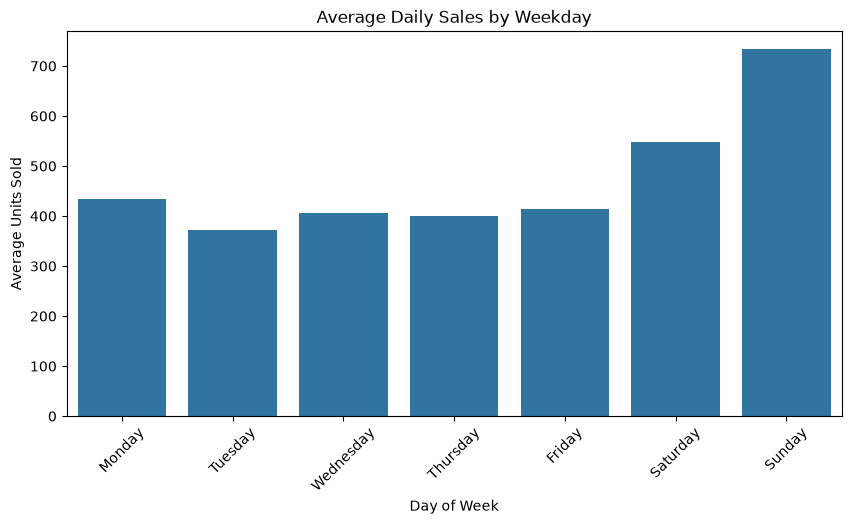

In [22]:
# Visualization
plt.figure(figsize=(10, 5))
sns.barplot(x=weekday_sales.index, y=weekday_sales.values)

plt.title("Average Daily Sales by Weekday")
plt.xlabel("Day of Week")
plt.ylabel("Average Units Sold")
plt.xticks(rotation=45)
plt.show()

### 4. Sales Distribution

Analyze daily sales quantity distribution across selected products to understand demand variability and identify potential outliers.

In [23]:
# Daily quantity sold per product
daily_product_sales = (
    bakery.groupby(["date", "article"])["Quantity"]
    .sum()
    .reset_index()
)

daily_product_sales.head()

,date,article,Quantity
0,2021-01-02,BAGUETTE,46.0
1,2021-01-02,BANETTE,40.0
2,2021-01-02,BOULE 400G,11.0
3,2021-01-02,BRIOCHE,2.0
4,2021-01-02,CAMPAGNE,10.0


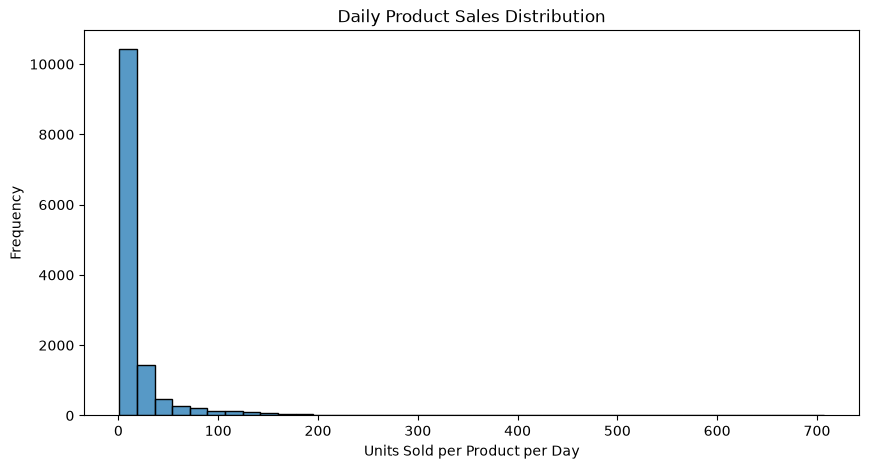

In [24]:
# Sales distribution
plt.figure(figsize=(10, 5))
sns.histplot(data=daily_product_sales, x="Quantity", bins=40)

plt.title("Daily Product Sales Distribution")
plt.xlabel("Units Sold per Product per Day")
plt.ylabel("Frequency")
plt.show()

In [25]:
# Summary statistics
display(daily_product_sales["Quantity"].describe())

count    13493.000000
mean        21.177351
std         48.907321
min          1.000000
25%          4.000000
50%          7.000000
75%         16.000000
max        707.000000
Name: Quantity, dtype: float64

In [26]:
# Check missing product-day values
expected = bakery["date"].nunique() * bakery["article"].nunique()
actual = len(daily_product_sales)

print("Expected product-days:", expected)
print("Recorded product-days:", actual)
print("Missing product-days:", expected - actual)

Expected product-days: 15600
Recorded product-days: 13493
Missing product-days: 2107


In [27]:
# Number of days with sales per product
product_days = (
    bakery.groupby("article")["date"]
    .nunique()
    .sort_values()
)

display(product_days)

article
GD KOUIGN AMANN         309
TRAITEUR                315
DIVERS VIENNOISERIE     329
VIK BREAD               365
GRAND FAR BRETON        405
FINANCIER X5            449
ECLAIR                  469
KOUIGN AMANN            486
SAND JB EMMENTAL        493
BRIOCHE                 513
SANDWICH COMPLET        528
FORMULE SANDWICH        543
TARTELETTE              551
PAIN AUX RAISINS        582
PAIN BANETTE            590
COMPLET                 592
MOISSON                 592
CEREAL BAGUETTE         595
CAMPAGNE                595
BOULE 400G              597
SPECIAL BREAD           598
PAIN AU CHOCOLAT        598
CROISSANT               599
BANETTE                 600
BAGUETTE                600
TRADITIONAL BAGUETTE    600
Name: date, dtype: int64

In [28]:
# Save daily product sales
daily_product_sales.to_csv("daily_product_sales.csv", index=False)